<a href="https://colab.research.google.com/github/codewithshreya10/AI-Lab-Programs/blob/main/Lab%20Assignment%2012.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Best k: 3, CV Accuracy: 0.958



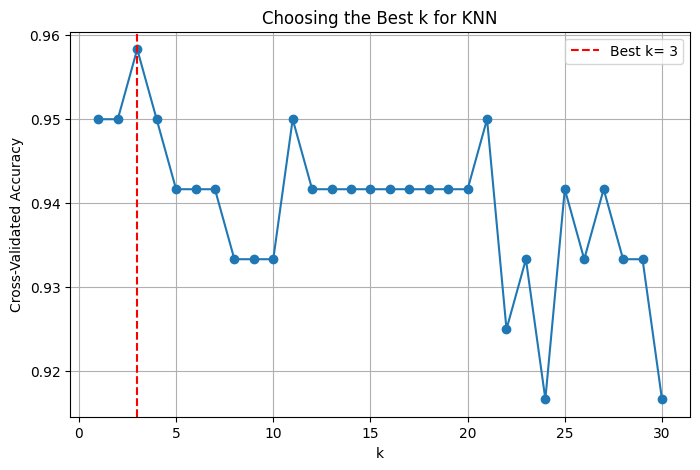

Accuracy: 1.00

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00         9
   virginica       1.00      1.00      1.00        11

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



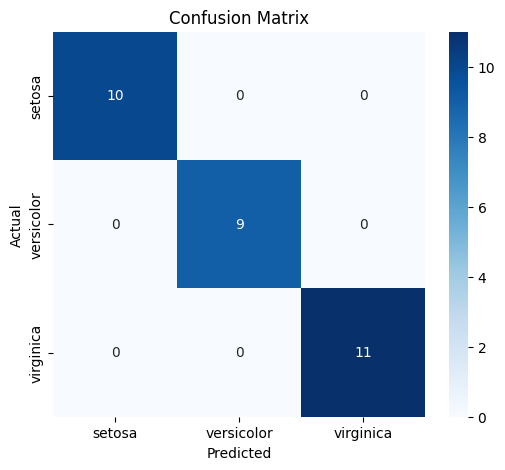


Predicted for [5.1, 3.5, 1.4, 0.2]: setosa


In [2]:
import matplotlib.pyplot as plt
import numpy as np
from collections import Counter
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns

iris = load_iris()
x, y = iris.data, iris.target
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)
k_values = range(1, 31)
cv_scores = []
for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    scores = cross_val_score(knn, x_train, y_train, cv=5, scoring='accuracy')
    cv_scores.append(scores.mean())
best_k = k_values[np.argmax(cv_scores)]
print(f"Best k: {best_k}, CV Accuracy: {max(cv_scores):.3f}\n")
plt.figure(figsize=(8, 5))
plt.plot(k_values, cv_scores, marker='o')
plt.axvline(best_k, color='red', linestyle='--', label=f'Best k= {best_k}')
plt.xlabel('k')
plt.ylabel('Cross-Validated Accuracy')
plt.title('Choosing the Best k for KNN')
plt.legend()
plt.grid(True)
plt.show()

knn_final = KNeighborsClassifier(n_neighbors=best_k, weights='distance')
knn_final.fit(x_train, y_train)
y_pred = knn_final.predict(x_test)
acc = accuracy_score(y_test, y_pred)
print(f"Accuracy: {acc:.2f}\n")
print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=iris.target_names))
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=iris.target_names, yticklabels=iris.target_names)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

new_sample = [[5.1, 3.5, 1.4, 0.2]]
prediction = knn_final.predict(new_sample)
print(f"\nPredicted for {new_sample[0]}: {iris.target_names[prediction[0]]}")